## EDA

In [16]:
import geopandas as gpd

print(gpd.__version__)

1.1.4


In [17]:
url = "https://anrmaps.vermont.gov/arcgis/rest/services/map_services/ACCD_OpenData/MapServer/16/query?outFields=*&where=1%3D1&f=geojson"

In [18]:
gdf = gpd.read_file(url)

In [19]:
gdf.shape

(242, 16)

In [20]:
gdf.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [21]:
gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   OBJECTID      242 non-null    int32   
 1   Town          242 non-null    str     
 2   Address       242 non-null    str     
 3   State         242 non-null    str     
 4   Bus_building  242 non-null    str     
 5   AwardType     242 non-null    str     
 6   Allocated     242 non-null    int32   
 7   Total_Cost    242 non-null    int32   
 8   Descript      242 non-null    str     
 9   Photo         64 non-null     str     
 10  Status        242 non-null    str     
 11  YearAwarded   242 non-null    int32   
 12  GlobalID      242 non-null    str     
 13  ATTACHMENT_1  242 non-null    int32   
 14  JPG_NAMES     20 non-null     str     
 15  geometry      242 non-null    geometry
dtypes: geometry(1), int32(5), str(10)
memory usage: 25.7 KB


In [22]:
gdf["JPG_NAMES"].dropna()

222      BarnesGilbertHouseBarn.jpg
223            BastionDielBarn.jpeg
224               BirdsongFlora.jpg
225                   BloodFarm.jpg
226                 CotterFarm.jpeg
227             DouglasOrchards.JPG
228                HillViewFarm.jpg
229           JoshuaJaquithFarm.png
230                    KingFarm.png
231              HenryGouldFarm.jpg
232      Ladd-ShedrickHouseBarn.jpg
233        LEStrattonMarketBarn.jpg
234                 PriestFarm.jpeg
235            OscarJohnsonFarm.jpg
236              ScotchBurnFarm.jpg
237    Smith-LathromFarmComplex.jpg
238                  SibleyFarm.jpg
239     WhitehillStoneHouseBarn.jpg
240                WaysideFarm.jpeg
241        SadawgaLakeHouseBarn.jpg
Name: JPG_NAMES, dtype: str

In [23]:
gdf["AwardType"].value_counts(dropna=False)

AwardType
Barn Grant    242
Name: count, dtype: int64

In [24]:
gdf["Status"].value_counts(dropna=False)

Status
Awarded    242
Name: count, dtype: int64

In [25]:
gdf[["Town", "Allocated", "Total_Cost", "YearAwarded"]].describe(include="all")

,Town,Allocated,Total_Cost,YearAwarded
count,242,242.000000,242.000000,242.000000
unique,128,NaN,NaN,NaN
top,Barnet,NaN,NaN,NaN
freq,7,NaN,NaN,NaN
mean,NaN,13876.904959,41596.690083,2020.768595
std,NaN,4617.470202,41208.301288,3.476681
min,NaN,1000.000000,2000.000000,2015.000000
25%,NaN,13273.000000,27207.500000,2018.000000
50%,NaN,15000.000000,36500.000000,2021.000000
75%,NaN,15000.000000,46255.000000,2024.000000


## Using .loc[] and .idxmax()
### .loc[] retrieves an entire record from our dataset
### .idxmax() finds the index of the maximum value

In [27]:
gdf.loc[gdf["Total_Cost"].idxmax()]

OBJECTID                                                    13138
Town                                                    Woodstock
Address                                        128 King Farm Road
State                                                     Vermont
Bus_building                                            King Farm
AwardType                                              Barn Grant
Allocated                                                   20000
Total_Cost                                                 543000
Descript        Jabez King bought this farm in 1807 and worked...
Photo                                                KingFarm.png
Status                                                    Awarded
YearAwarded                                                  2026
GlobalID                   {F15A86FA-DF78-407F-A958-40F1007EA677}
ATTACHMENT_1                                                 3644
JPG_NAMES                                            KingFarm.png
geometry  

In [28]:
url2 = "https://anrmaps.vermont.gov/arcgis/rest/services/map_services/ACCD_DHCD_PlanningAtlas/MapServer/13/query?where=1%3D1&outFields=*&f=geojson"

historic = gpd.read_file(url2)

historic.shape

(425, 16)

In [29]:
historic.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   OBJECTID      425 non-null    int32   
 1   Town          425 non-null    str     
 2   Address       425 non-null    str     
 3   State         425 non-null    str     
 4   Bus_building  425 non-null    str     
 5   AwardType     425 non-null    str     
 6   Allocated     425 non-null    float64 
 7   Total_Cost    425 non-null    int32   
 8   Descript      425 non-null    str     
 9   Photo         105 non-null    str     
 10  Status        425 non-null    str     
 11  YearAwarded   425 non-null    int32   
 12  GlobalID      425 non-null    str     
 13  ATTACHMENT_1  425 non-null    int32   
 14  JPG_NAMES     20 non-null     str     
 15  geometry      425 non-null    geometry
dtypes: float64(1), geometry(1), int32(4), str(10)
memory usage: 46.6 KB


In [30]:
historic["YearAwarded"].describe()

count     425.000000
mean     2020.609412
std         3.382517
min      2015.000000
25%      2018.000000
50%      2021.000000
75%      2023.000000
max      2026.000000
Name: YearAwarded, dtype: float64

In [31]:
historic["YearAwarded"].value_counts().sort_index()

YearAwarded
2015    38
2016    31
2017    32
2018    33
2019    29
2020    35
2021    33
2022    41
2023    48
2024    40
2025    45
2026    20
Name: count, dtype: int64

In [32]:
historic["AwardType"].value_counts(dropna=False)

AwardType
Barn Grant                     242
Historic Preservation Grant    183
Name: count, dtype: int64

## Historical Barn Grant Master List
### I reached out directly to the Vermont Agency of Commerce & Community Development to see if there was a more comprehensive record list as the feature services only covered 2015-2026 and the barn program was established in 1992 - hoping to find those earlier records. They provided me a "Barn Grants Master List" only it did not have geocoded barn locations, rather town names, and tons of formatting issues as you can see through the dataframe below.

In [33]:
import pandas as pd
master = pd.read_excel("../data/raw/Barn Grants Master List.xlsx")

In [34]:
master.head(10)

,Barn Preservation Grants - Master List,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 16374,Unnamed: 16375,Unnamed: 16376,Unnamed: 16377,Unnamed: 16378,Unnamed: 16379,Unnamed: 16380,Unnamed: 16381,Unnamed: 16382,Unnamed: 16383
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,Total Grants Awarded,5729397.5,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,Total Grants Paid,5024941.08,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,Total Project Cost,16585368.66,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,Total Projects,547,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,FY 2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,Grant Number,Town,County,Name,Grant Amount,Total Project Cost,Date Completed,Amount Paid,Recaptured,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,BG26-001,Andover,Windsor,Joshua Jaquith Farm,20000,50000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,BG26-003,Brattleboro,Windham,Cotter Farm,19075,38150,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
master_raw = pd.read_excel(
    "../data/raw/Barn Grants Master List.xlsx",
    header=None,
    usecols="A:I"
)

In [36]:
master_raw.head(20)

,0,1,2,3,4,5,6,7,8
0,Barn Preservation Grants - Master List,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,Total Grants Awarded,5729397.5,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,Total Grants Paid,5024941.08,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,Total Project Cost,16585368.66,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,Total Projects,547,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,FY 2026,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Grant Number,Town,County,Name,Grant Amount,Total Project Cost,Date Completed,Amount Paid,Recaptured
9,BG26-001,Andover,Windsor,Joshua Jaquith Farm,20000,50000,NaN,NaN,NaN


In [37]:
master_raw[0].head(30)

0     Barn Preservation Grants - Master List
1                                        NaN
2                                        NaN
3                                        NaN
4                                        NaN
5                                        NaN
6                                        NaN
7                                    FY 2026
8                               Grant Number
9                                   BG26-001
10                                  BG26-003
11                                  BG26-004
12                                  BG26-006
13                                  BG26-007
14                                  BG26-009
15                                  BG26-012
16                                  BG26-014
17                                  BG26-017
18                                  BG26-018
19                                  BG26-019
20                                  BG26-020
21                                  BG26-021
22        

In [38]:
master_raw[master_raw[0].astype(str).str.contains("FY", na=False)][0]

7      FY 2026
31     FY 2025
59     FY 2024
84     FY 2023
117    FY 2022
144    FY 2021
168    FY 2020
191    FY 2019
213    FY 2018
234    FY 2017
256    FY 2016
281    FY 2015
306    FY 2014
335    FY 2013
358    FY 2012
378    FY 2011
405    FY 2010
437    FY 2009
460    FY 2008
491    FY 2007
516    FY 2006
534    FY 2005
557    FY 2004
580    FY 2003
602    FY 2002
630    FY 2001
653    FY 2000
664    FY 1999
677    FY 1998
694    FY 1997
Name: 0, dtype: object

In [39]:
master_raw["Year"] = master_raw[0].str.extract(r"FY (\d{4})")

In [40]:
master_raw[[0, "Year"]].head(35)

,0,Year
0,Barn Preservation Grants - Master List,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,FY 2026,2026
8,Grant Number,NaN
9,BG26-001,NaN


In [41]:
master_raw["Year"] = master_raw["Year"].ffill()

In [42]:
master_raw[[0, "Year"]].head(35)

,0,Year
0,Barn Preservation Grants - Master List,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,FY 2026,2026
8,Grant Number,2026
9,BG26-001,2026


In [43]:
master_raw[master_raw[0].astype(str).str.startswith("BG")][[0, "Year"]].head(20)

,0,Year
9,BG26-001,2026
10,BG26-003,2026
11,BG26-004,2026
12,BG26-006,2026
13,BG26-007,2026
14,BG26-009,2026
15,BG26-012,2026
16,BG26-014,2026
17,BG26-017,2026
18,BG26-018,2026


In [44]:
grants = master_raw[
    master_raw[0].astype(str).str.startswith("BG")
].copy()

In [45]:
grants.shape

(619, 10)

In [46]:
grants.head(10)

,0,1,2,3,4,5,6,7,8,Year
9,BG26-001,Andover,Windsor,Joshua Jaquith Farm,20000,50000,NaN,NaN,NaN,2026
10,BG26-003,Brattleboro,Windham,Cotter Farm,19075,38150,NaN,NaN,NaN,2026
11,BG26-004,Bristol,Addison,Smith-Lathrop Complex,20000,40000,NaN,NaN,NaN,2026
12,BG26-006,Danville,Caledonia,Hill View Farm,20000,45198,NaN,NaN,NaN,2026
13,BG26-007,East Montpelier,Washington,Sibley Farm,9750,19500,NaN,NaN,NaN,2026
14,BG26-009,Hyde Park,Lamoille,Birdsong Flora,20000,50200,NaN,NaN,NaN,2026
15,BG26-012,Morristown,Lamoille,"Priest Farm, Harlequin Farm",20000,40645,NaN,NaN,NaN,2026
16,BG26-014,Newfane,Windham,L. E. Stratton Market Barn,20000,72500,NaN,NaN,NaN,2026
17,BG26-017,Pownal,Bennington,Bastion Diel Barn,20000,40000,NaN,NaN,NaN,2026
18,BG26-018,Putney,Windham,Blood Farm,20000,90000,NaN,NaN,NaN,2026


In [47]:
grants[0].value_counts().head(20)

0
BG92-02     2
BG26-001    1
BG26-003    1
BG26-004    1
BG26-006    1
BG26-007    1
BG26-009    1
BG26-012    1
BG26-014    1
BG26-017    1
BG26-018    1
BG26-019    1
BG26-020    1
BG26-021    1
BG26-022    1
BG26-024    1
BG26-025    1
BG26-026    1
BG26-027    1
BG26-028    1
Name: count, dtype: int64

In [48]:
grants[[0, "Year"]].tail(100)

,0,Year
624,BG02-50,2002
625,BG02-53,2002
626,BG02-57,2002
627,BG02-60,2002
632,BG01-04,2001
...,...,...
755,BG92-02,1997
756,BG92-03,1997
757,BG92-04,1997
758,BG92-05,1997


In [49]:
grant_mask = master_raw[0].astype(str).str.match(r"^BG\d{2}-\d+$")

grant_mask.sum()

np.int64(616)

## Load Cleaned Master Grant Data

In [50]:
import pandas as pd
grants_cleaned = pd.read_csv(
    "../data/processed/cleaned_barn_grants_master.csv")
grants_cleaned.shape

(619, 25)

In [51]:
grants_cleaned.columns

Index(['grant_id', 'grant_id_original', 'year', 'fy_section_label',
       'grant_id_encoded_year', 'town', 'county', 'property_name',
       'grant_amount', 'grant_amount_original', 'total_project_cost',
       'total_project_cost_original', 'date_completed',
       'date_completed_original', 'amount_paid', 'amount_paid_original',
       'recaptured', 'recaptured_original', 'completion_status_inferred',
       'qa_flags', 'source_workbook', 'source_sheet', 'source_row',
       'administrative_source', 'notes'],
      dtype='str')

In [52]:
grants_cleaned.head()

,grant_id,grant_id_original,year,fy_section_label,grant_id_encoded_year,town,county,property_name,grant_amount,grant_amount_original,...,amount_paid_original,recaptured,recaptured_original,completion_status_inferred,qa_flags,source_workbook,source_sheet,source_row,administrative_source,notes
0,BG26-001,BG26-001,2026,FY 2026,2026,Andover,Windsor,Joshua Jaquith Farm,20000.0,20000.0,...,NaN,NaN,NaN,open_or_not_yet_completed,NaN,Barn Grants Master List_official_2026-10-05.xlsx,Sheet1,10,Official VDHP Barn Grants Master List supplied...,NaN
1,BG26-003,BG26-003,2026,FY 2026,2026,Brattleboro,Windham,Cotter Farm,19075.0,19075.0,...,NaN,NaN,NaN,open_or_not_yet_completed,NaN,Barn Grants Master List_official_2026-10-05.xlsx,Sheet1,11,Official VDHP Barn Grants Master List supplied...,NaN
2,BG26-004,BG26-004,2026,FY 2026,2026,Bristol,Addison,Smith-Lathrop Complex,20000.0,20000.0,...,NaN,NaN,NaN,open_or_not_yet_completed,NaN,Barn Grants Master List_official_2026-10-05.xlsx,Sheet1,12,Official VDHP Barn Grants Master List supplied...,NaN
3,BG26-006,BG26-006,2026,FY 2026,2026,Danville,Caledonia,Hill View Farm,20000.0,20000.0,...,NaN,NaN,NaN,open_or_not_yet_completed,NaN,Barn Grants Master List_official_2026-10-05.xlsx,Sheet1,13,Official VDHP Barn Grants Master List supplied...,NaN
4,BG26-007,BG26-007,2026,FY 2026,2026,East Montpelier,Washington,Sibley Farm,9750.0,9750.0,...,NaN,NaN,NaN,open_or_not_yet_completed,NaN,Barn Grants Master List_official_2026-10-05.xlsx,Sheet1,14,Official VDHP Barn Grants Master List supplied...,NaN


In [53]:
grants_cleaned["county"] = grants_cleaned["county"].replace({
    "Fraklin": "Franklin",
    "Wasington": "Washington"
})
print(sorted(grants_cleaned["county"].dropna().unique()))

['Addison', 'Bennington', 'Caledonia', 'Chittenden', 'Essex', 'Franklin', 'Grand Isle', 'Lamoille', 'Orange', 'Orleans', 'Rutland', 'Washington', 'Windham', 'Windsor']


In [54]:
print(sorted(grants_cleaned["town"].dropna().unique()))

['Addison', 'Albany', 'Alburgh', 'Andover', 'Arlington', 'Barnet', 'Barre', 'Barton', 'Bellows Falls', 'Belmont', 'Bennington', 'Benson', 'Berkshire', 'Berlin', 'Bethel', 'Bloomfield', 'Bolton', 'Braintree', 'Brandon', 'Brattleboro', 'Bridport', 'Bristol', 'Brookfield', 'Brownington', 'Brownsville', 'Burke', 'Burlington', 'Cabot', 'Calais', 'Cambridge', 'Canaan', 'Castleton', 'Cavendish', 'Charlotte', 'Chelsea', 'Chester', 'Chittenden', 'Clarendon', 'Colchester', 'Corinth', 'Cornwall', 'Coventry', 'Craftsbury', 'Danville', 'Derby', 'Dorset', 'Dummerston', 'E. Corinth', 'E. Montpelier', 'East Barre', 'East Brookfield', 'East Burke', 'East Corinth', 'East Dummerston', 'East Montpelier', 'East Ryegate', 'East Topsham', 'Enosburg', 'Essex', 'Essex Junction', 'Fairfax', 'Fairfield', 'Fairlee', 'Fayston', 'Ferrisburgh', 'Fletcher', 'Florence', 'Franklin', 'Gaysville', 'Georgia', 'Glover', 'Gover', 'Grafton', 'Grand Isle', 'Granville', 'Greensboro', 'Groton', 'Guildhall', 'Guilford', 'Halifax

In [55]:
import geopandas as gpd
vt_towns = gpd.read_file("../data/raw/tl_2025_50_cousub.zip")
vt_towns.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 256 entries, 0 to 255
Data columns (total 17 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   STATEFP   256 non-null    str     
 1   COUNTYFP  256 non-null    str     
 2   COUSUBFP  256 non-null    str     
 3   COUSUBNS  256 non-null    str     
 4   GEOID     256 non-null    str     
 5   GEOIDFQ   256 non-null    str     
 6   NAME      256 non-null    str     
 7   NAMELSAD  256 non-null    str     
 8   LSAD      256 non-null    str     
 9   CLASSFP   256 non-null    str     
 10  MTFCC     256 non-null    str     
 11  FUNCSTAT  256 non-null    str     
 12  ALAND     256 non-null    int64   
 13  AWATER    256 non-null    int64   
 14  INTPTLAT  256 non-null    str     
 15  INTPTLON  256 non-null    str     
 16  geometry  256 non-null    geometry
dtypes: geometry(1), int64(2), str(14)
memory usage: 34.1 KB


In [56]:
vt_towns.head()

,STATEFP,COUNTYFP,COUSUBFP,COUSUBNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,50,015,23500,01462088,5001523500,0600000US5001523500,Eden,Eden town,43,T1,G4040,A,162970286,2552928,+44.7144313,-072.5394153,"POLYGON ((-72.66139 44.70192, -72.66084 44.702..."
1,50,025,48400,01462159,5002548400,0600000US5002548400,Newfane,Newfane town,43,T1,G4040,A,102981054,697246,+42.9727535,-072.7040391,"POLYGON ((-72.7755 42.92638, -72.77376 42.9292..."
2,50,025,60250,01462189,5002560250,0600000US5002560250,Rockingham,Rockingham town,43,T1,G4040,A,107252397,2011216,+43.1704749,-072.5065934,"POLYGON ((-72.55798 43.12776, -72.55798 43.128..."
3,50,025,81400,01462253,5002581400,0600000US5002581400,Westminster,Westminster town,43,T1,G4040,A,116613918,669527,+43.0746825,-072.5080568,"POLYGON ((-72.58564 43.02324, -72.58491 43.027..."
4,50,025,84850,01462265,5002584850,0600000US5002584850,Windham,Windham town,43,T1,G4040,A,67581474,211573,+43.1738019,-072.7013584,"POLYGON ((-72.77335 43.1539, -72.77256 43.1547..."


In [57]:
print(vt_towns[["NAME", "NAMELSAD", "GEOID"]].head(20))

           NAME          NAMELSAD       GEOID
0          Eden         Eden town  5001523500
1       Newfane      Newfane town  5002548400
2    Rockingham   Rockingham town  5002560250
3   Westminster  Westminster town  5002581400
4       Windham      Windham town  5002584850
5     Brookline    Brookline town  5002509475
6         Dover        Dover town  5002517875
7       Grafton      Grafton town  5002528900
8      Guilford     Guilford town  5002530925
9      Bradford     Bradford town  5001707375
10      Corinth      Corinth town  5001715700
11      Fairlee      Fairlee town  5001725675
12       Orange       Orange town  5001753425
13     Randolph     Randolph town  5001758075
14    Strafford    Strafford town  5001770675
15       Putney       Putney town  5002557700
16       Vernon       Vernon town  5002574800
17    Berkshire    Berkshire town  5001105425
18    Enosburgh    Enosburgh town  5001124050
19    Fairfield    Fairfield town  5001125225


In [58]:
caitlin_towns = set(grants_cleaned["town"].dropna().unique())
census_towns = set(vt_towns["NAME"].dropna().unique())

unmatched_towns = sorted(caitlin_towns - census_towns)

print(unmatched_towns)
print("Unmatched:", len(unmatched_towns))

['Bellows Falls', 'Belmont', 'Brownsville', 'E. Corinth', 'E. Montpelier', 'East Barre', 'East Brookfield', 'East Burke', 'East Corinth', 'East Dummerston', 'East Ryegate', 'East Topsham', 'Enosburg', 'Florence', 'Gaysville', 'Gover', 'Island Pond', 'Isle la Motte', 'Jacksonville', 'Jeffersonville', 'Morrisville', 'Mt. Holly', 'N. Bennington', 'N. Clarendon', 'N. Hartland', 'North Pomfret', 'North Thetford', 'Perkinsville', 'Pownall', 'S. Burlington', 'S. Londonderry', 'S. Royalton', 'S. Woodstock', 'South Londonderry', 'South Newbury', 'South Pomfret', 'South Ryegate', 'Taftsville', 'W. Brattleboro', 'W. Fairlee', 'West Brattleboro', 'West Danville', 'West Glover', 'Wilder (Hartford)', 'Williamsville']
Unmatched: 45


In [59]:
grants_cleaned["town_original"] = grants_cleaned["town"]
grants_cleaned["census_town"] = grants_cleaned["town"]

## The Historical Grant Data names were slightly different than the census town names. Here I'm matching those so I can perform a join later

In [60]:
town_crosswalk = {
    "E. Corinth": "Corinth",
    "E. Montpelier": "East Montpelier",
    "East Corinth": "Corinth",
    "Enosburg": "Enosburgh",
    "Gover": "Glover",
    "Isle la Motte": "Isle La Motte",
    "Mt. Holly": "Mount Holly",
    "Pownall": "Pownal",
    "S. Burlington": "South Burlington"
}

In [61]:
grants_cleaned["census_town"] = grants_cleaned["census_town"].replace(town_crosswalk)

In [62]:
unmatched_towns = sorted(
    set(grants_cleaned["census_town"].dropna().unique()) - census_towns
)

print(unmatched_towns)
print("Unmatched:", len(unmatched_towns))

['Bellows Falls', 'Belmont', 'Brownsville', 'East Barre', 'East Brookfield', 'East Burke', 'East Dummerston', 'East Ryegate', 'East Topsham', 'Florence', 'Gaysville', 'Island Pond', 'Jacksonville', 'Jeffersonville', 'Morrisville', 'N. Bennington', 'N. Clarendon', 'N. Hartland', 'North Pomfret', 'North Thetford', 'Perkinsville', 'S. Londonderry', 'S. Royalton', 'S. Woodstock', 'South Londonderry', 'South Newbury', 'South Pomfret', 'South Ryegate', 'Taftsville', 'W. Brattleboro', 'W. Fairlee', 'West Brattleboro', 'West Danville', 'West Glover', 'Wilder (Hartford)', 'Williamsville']
Unmatched: 36


In [63]:
town_crosswalk.update({
    "Bellows Falls": "Rockingham",
    "Belmont": "Mount Holly",
    "Brownsville": "West Windsor",
    "East Barre": "Barre",
    "East Brookfield": "Brookfield",
    "East Burke": "Burke",
    "East Dummerston": "Dummerston",
    "East Ryegate": "Ryegate",
    "East Topsham": "Topsham",
    "Florence": "Pittsford",
    "Gaysville": "Stockbridge",
    "Island Pond": "Brighton",
    "Jacksonville": "Whitingham",
    "Jeffersonville": "Cambridge",
    "Morrisville": "Morristown",
    "N. Bennington": "Bennington",
    "N. Clarendon": "Clarendon",
    "N. Hartland": "Hartland",
    "North Pomfret": "Pomfret",
    "North Thetford": "Thetford",
    "Perkinsville": "Weathersfield",
    "S. Londonderry": "Londonderry",
    "S. Royalton": "Royalton",
    "S. Woodstock": "Woodstock",
    "South Londonderry": "Londonderry",
    "South Newbury": "Newbury",
    "South Pomfret": "Pomfret",
    "South Ryegate": "Ryegate",
    "Taftsville": "Woodstock",
    "W. Brattleboro": "Brattleboro",
    "W. Fairlee": "Fairlee",
    "West Brattleboro": "Brattleboro",
    "West Danville": "Danville",
    "West Glover": "Glover",
    "Wilder (Hartford)": "Hartford",
    "Williamsville": "Newfane"
})

In [64]:
grants_cleaned["census_town"] = grants_cleaned["census_town"].replace(town_crosswalk)

In [65]:
unmatched_towns = sorted(
    set(grants_cleaned["census_town"].dropna().unique()) - census_towns
)

print(unmatched_towns)
print("Unmatched:", len(unmatched_towns))

[]
Unmatched: 0


In [66]:
town_grants = grants_cleaned.groupby("town").agg(
    grant_count=("grant_id", "count"),
    total_awarded=("grant_amount", "sum")
).reset_index()

town_grants.head()

,town,grant_count,total_awarded
0,Addison,2,25645.0
1,Albany,3,13565.0
2,Alburgh,2,7250.0
3,Andover,2,35000.0
4,Arlington,3,36450.0


In [67]:
grants_cleaned["grant_amount"].isna().sum()

np.int64(89)

In [68]:
town_grants = grants_cleaned.groupby("census_town").agg(
    grant_count=("grant_id", "count"),
    grants_with_amount=("grant_amount", "count"),
    total_awarded=("grant_amount", "sum")
).reset_index()

In [69]:
town_grants["grants_missing_amount"] = (
    town_grants["grant_count"] - town_grants["grants_with_amount"]
)
town_grants.head()

,census_town,grant_count,grants_with_amount,total_awarded,grants_missing_amount
0,Addison,2,2,25645.0,0
1,Albany,3,1,13565.0,2
2,Alburgh,2,1,7250.0,1
3,Andover,2,2,35000.0,0
4,Arlington,3,3,36450.0,0


In [70]:
town_grants_gdf = vt_towns.merge(
    town_grants,
    left_on="NAME",
    right_on="census_town",
    how="left"
)
town_grants_gdf.head()

,STATEFP,COUNTYFP,COUSUBFP,COUSUBNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,...,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,census_town,grant_count,grants_with_amount,total_awarded,grants_missing_amount
0,50,015,23500,01462088,5001523500,0600000US5001523500,Eden,Eden town,43,T1,...,162970286,2552928,+44.7144313,-072.5394153,"POLYGON ((-72.66139 44.70192, -72.66084 44.702...",NaN,NaN,NaN,NaN,NaN
1,50,025,48400,01462159,5002548400,0600000US5002548400,Newfane,Newfane town,43,T1,...,102981054,697246,+42.9727535,-072.7040391,"POLYGON ((-72.7755 42.92638, -72.77376 42.9292...",Newfane,4.0,4.0,60000.0,0.0
2,50,025,60250,01462189,5002560250,0600000US5002560250,Rockingham,Rockingham town,43,T1,...,107252397,2011216,+43.1704749,-072.5065934,"POLYGON ((-72.55798 43.12776, -72.55798 43.128...",Rockingham,5.0,3.0,35000.0,2.0
3,50,025,81400,01462253,5002581400,0600000US5002581400,Westminster,Westminster town,43,T1,...,116613918,669527,+43.0746825,-072.5080568,"POLYGON ((-72.58564 43.02324, -72.58491 43.027...",Westminster,3.0,2.0,20000.0,1.0
4,50,025,84850,01462265,5002584850,0600000US5002584850,Windham,Windham town,43,T1,...,67581474,211573,+43.1738019,-072.7013584,"POLYGON ((-72.77335 43.1539, -72.77256 43.1547...",NaN,NaN,NaN,NaN,NaN


In [71]:
town_grants_gdf[
    ["NAME", "grant_count", "total_awarded", "grants_missing_amount"]
].info()

<class 'pandas.DataFrame'>
RangeIndex: 256 entries, 0 to 255
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   NAME                   256 non-null    str    
 1   grant_count            173 non-null    float64
 2   total_awarded          173 non-null    float64
 3   grants_missing_amount  173 non-null    float64
dtypes: float64(3), str(1)
memory usage: 8.1 KB


In [72]:
print(town_grants_gdf["grant_count"].notna().sum())
print(town_grants_gdf["grant_count"].isna().sum())

173
83


# Getting the Census Data

In [73]:
import os
from dotenv import load_dotenv
load_dotenv("../.env")
census_api_key = os.getenv("CENSUS_API_KEY")

In [74]:
print(census_api_key is not None)

True


In [75]:
import requests

acs_url = (
    "https://api.census.gov/data/2024/acs/acs5"
    "?get=NAME,B19013_001E"
    "&for=county%20subdivision:*"
    "&in=state:50"
)

response = requests.get(acs_url, params={"key": census_api_key})
acs_data = response.json()

In [76]:
response = requests.get(
    acs_url,
    params={"key": census_api_key}
)

response.raise_for_status()
acs_data = response.json()

acs_data[:5]

[['NAME', 'B19013_001E', 'state', 'county', 'county subdivision'],
 ['Addison town, Addison County, Vermont', '106667', '50', '001', '00325'],
 ['Bridport town, Addison County, Vermont', '83214', '50', '001', '08575'],
 ['Bristol town, Addison County, Vermont', '74620', '50', '001', '09025'],
 ['Cornwall town, Addison County, Vermont', '114583', '50', '001', '16000']]

In [77]:
acs_df = pd.DataFrame(
    acs_data[1:],
    columns=acs_data[0]
)

acs_df.head()

,NAME,B19013_001E,state,county,county subdivision
0,"Addison town, Addison County, Vermont",106667,50,001,00325
1,"Bridport town, Addison County, Vermont",83214,50,001,08575
2,"Bristol town, Addison County, Vermont",74620,50,001,09025
3,"Cornwall town, Addison County, Vermont",114583,50,001,16000
4,"Ferrisburgh town, Addison County, Vermont",106989,50,001,26300


In [78]:
acs_df

,NAME,B19013_001E,state,county,county subdivision
0,"Addison town, Addison County, Vermont",106667,50,001,00325
1,"Bridport town, Addison County, Vermont",83214,50,001,08575
2,"Bristol town, Addison County, Vermont",74620,50,001,09025
3,"Cornwall town, Addison County, Vermont",114583,50,001,16000
4,"Ferrisburgh town, Addison County, Vermont",106989,50,001,26300
...,...,...,...,...,...
251,"Weathersfield town, Windsor County, Vermont",83095,50,027,77500
252,"Weston town, Windsor County, Vermont",115000,50,027,82000
253,"West Windsor town, Windsor County, Vermont",108750,50,027,83050
254,"Windsor town, Windsor County, Vermont",52484,50,027,84925


In [79]:
acs_df = acs_df.rename(
    columns={"B19013_001E": "median_household_income"}
)

In [80]:
acs_df["median_household_income"] = pd.to_numeric(
    acs_df["median_household_income"],
    errors="coerce"
)

acs_df["GEOID"] = (
    acs_df["state"]
    + acs_df["county"]
    + acs_df["county subdivision"]
)

In [81]:
vt_analysis = town_grants_gdf.merge(
    acs_df[["GEOID", "median_household_income"]],
    on="GEOID",
    how="left",
    validate="one_to_one"
)

vt_analysis[
    ["NAME", "grant_count", "total_awarded", "median_household_income"]
].head()

,NAME,grant_count,total_awarded,median_household_income
0,Eden,NaN,NaN,83578
1,Newfane,4.0,60000.0,66719
2,Rockingham,5.0,35000.0,70857
3,Westminster,3.0,20000.0,71491
4,Windham,NaN,NaN,94500


In [82]:
print("Total towns:", len(vt_analysis))

print(
    "Towns missing income:",
    vt_analysis["median_household_income"].isna().sum()
)

print(
    "Towns with negative income values:",
    (vt_analysis["median_household_income"] < 0).sum()
)

Total towns: 256
Towns missing income: 0
Towns with negative income values: 9


In [83]:
vt_analysis.loc[
    vt_analysis["median_household_income"] < 0,
    ["NAME", "GEOID", "median_household_income"]
]

,NAME,GEOID,median_household_income
43,Lewis,5000939775,-666666666
45,Victory,5000975175,-666666666
46,Warren's,5000976562,-666666666
47,Warner's,5000976337,-666666666
49,Averill,5000902125,-666666666
50,Avery's,5000902162,-666666666
200,Glastenbury,5000327962,-666666666
210,Mount Tabor,5002147425,-666666666
213,Somerset,5002565762,-666666666


In [84]:
vt_analysis["median_household_income"] = (
    vt_analysis["median_household_income"]
    .replace(-666666666, float("nan"))
)

In [85]:
print(
    "Towns missing income:",
    vt_analysis["median_household_income"].isna().sum()
)

Towns missing income: 9


In [86]:
# Original Census data
acs_df.loc[
    acs_df["NAME"].str.contains("Addison town"),
    ["NAME", "GEOID", "median_household_income"]
]

,NAME,GEOID,median_household_income
0,"Addison town, Addison County, Vermont",5000100325,106667


In [87]:
# Joined geographic data
vt_analysis.loc[
    vt_analysis["NAME"] == "Addison",
    ["NAME", "GEOID", "median_household_income"]
]

,NAME,GEOID,median_household_income
233,Addison,5000100325,106667.0


In [88]:
mismatches = 0

for geoid in vt_analysis["GEOID"]:
    original = acs_df.loc[
        acs_df["GEOID"] == geoid,
        "median_household_income"
    ].iloc[0]

    joined = vt_analysis.loc[
        vt_analysis["GEOID"] == geoid,
        "median_household_income"
    ].iloc[0]

    if original != joined and not (original == -666666666 and pd.isna(joined)):
        mismatches += 1

print("Income mismatches:", mismatches)

Income mismatches: 0


In [89]:
vt_analysis["grant_count"] = vt_analysis["grant_count"].fillna(0).astype(int)

vt_analysis["total_awarded"] = vt_analysis["total_awarded"].fillna(0)

In [90]:
print("Towns with zero grants:", (vt_analysis["grant_count"] == 0).sum())

Towns with zero grants: 83


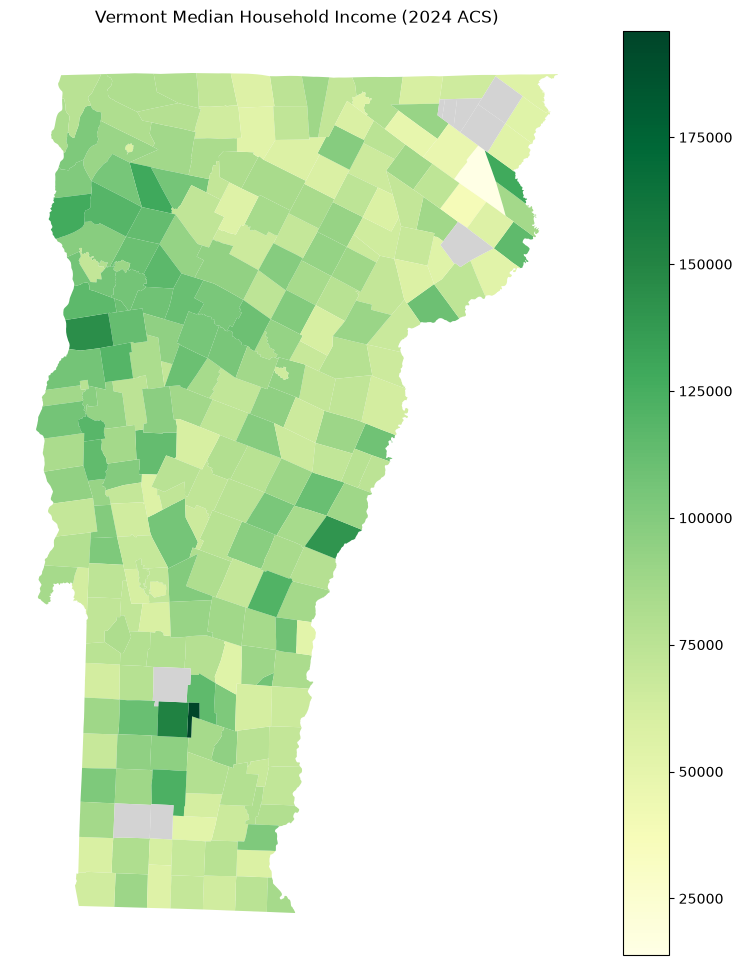

In [91]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 12))

vt_analysis.plot(
    column="median_household_income",
    cmap="YlGn",
    legend=True,
    missing_kwds={"color": "lightgrey"},
    ax=ax
)

ax.set_title("Vermont Median Household Income (2024 ACS)")
ax.set_axis_off()

plt.show()

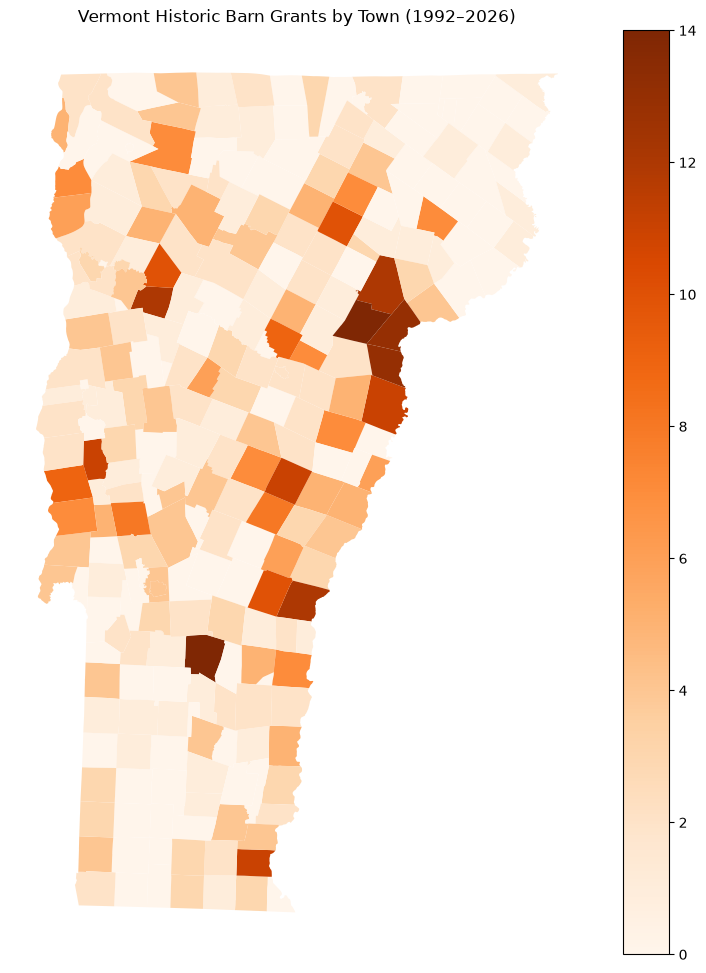

In [92]:
fig, ax = plt.subplots(figsize=(10, 12))

vt_analysis.plot(
    column="grant_count",
    cmap="Oranges",
    legend=True,
    ax=ax
)

ax.set_title("Vermont Historic Barn Grants by Town (1992–2026)")
ax.set_axis_off()

plt.show()

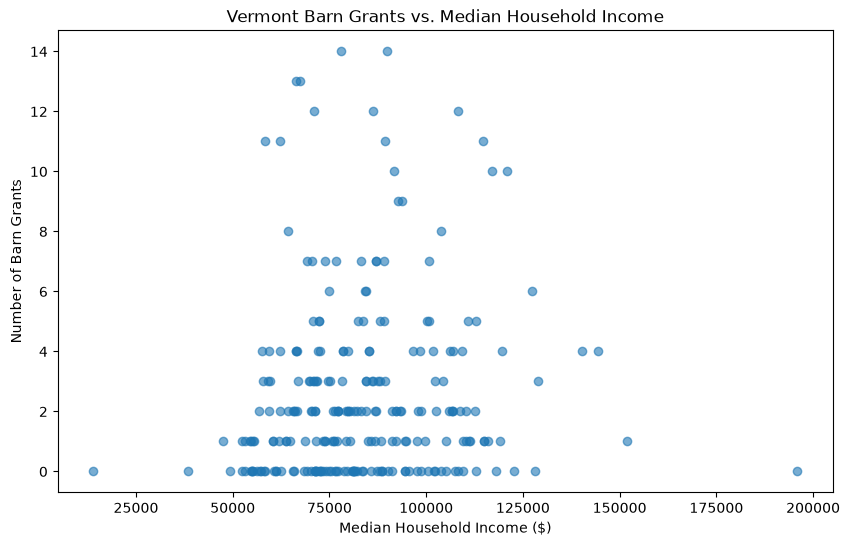

In [93]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    vt_analysis["median_household_income"],
    vt_analysis["grant_count"],
    alpha=0.6
)

ax.set_xlabel("Median Household Income ($)")
ax.set_ylabel("Number of Barn Grants")
ax.set_title("Vermont Barn Grants vs. Median Household Income")

plt.show()

## Now let's use the Pearson Correlation Coefficient and measure the strength and direction of the relationship (looks obviously not strong)

In [94]:
correlation = vt_analysis[
    ["median_household_income", "grant_count"]
].corr()

correlation

,median_household_income,grant_count
median_household_income,1.000000,0.095006
grant_count,0.095006,1.000000


In [95]:
vt_analysis[
    ["median_household_income", "total_awarded"]
].corr()

,median_household_income,total_awarded
median_household_income,1.000000,0.112461
total_awarded,0.112461,1.000000


In [96]:
towns_web = vt_analysis[
    [
        "GEOID",
        "NAME",
        "median_household_income",
        "grant_count",
        "total_awarded",
        "geometry"
    ]
].copy()

towns_web = towns_web.to_crs(epsg=4326)

towns_web.to_file(
    "../data/processed/vermont_towns.geojson",
    driver="GeoJSON"
)

In [97]:
import geopandas as gpd

towns_check = gpd.read_file("../data/processed/vermont_towns.geojson")

print(towns_check.shape)
print(towns_check.crs)

(256, 6)
EPSG:4326


In [98]:
import sys
print(sys.executable)

c:\Development\vermont-barn-grants\.venv\Scripts\python.exe


In [99]:
vt_analysis["median_household_income"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

count       247.000000
mean      83173.882591
std       21126.809304
min       13849.000000
25%       70129.500000
50%       80250.000000
75%       94693.000000
90%      109858.800000
95%      116635.000000
max      195938.000000
Name: median_household_income, dtype: float64

In [100]:
income = vt_analysis["median_household_income"].dropna()

breaks = income.quantile(
    [0, 1/7, 2/7, 3/7, 4/7, 5/7, 6/7, 1]
)

print(breaks.round(0))

0.000000     13849.0
0.142857     62146.0
0.285714     71216.0
0.428571     76875.0
0.571429     84375.0
0.714286     92288.0
0.857143    106607.0
1.000000    195938.0
Name: median_household_income, dtype: float64


In [101]:
barns = gpd.read_file("../web/data/barn_locations.geojson")
print(barns.columns.tolist())
print(barns.iloc[0].drop("geometry"))

['OBJECTID', 'Town', 'Address', 'State', 'Bus_building', 'AwardType', 'Allocated', 'Total_Cost', 'Descript', 'Photo', 'Status', 'YearAwarded', 'GlobalID', 'ATTACHMENT_1', 'JPG_NAMES', 'geometry']
OBJECTID                                                    11745
Town                                                       Barnet
Address                                     2742 US Route 5 South
State                                                     Vermont
Bus_building                                       Maplemont Farm
AwardType                                              Barn Grant
Allocated                                                   14400
Total_Cost                                                  28800
Descript        Constructed in 1936 to replace an earlier stru...
Photo                                                         NaN
Status                                                    Awarded
YearAwarded                                                  2016
GlobalID    

In [102]:
barns.columns.tolist()

['OBJECTID',
 'Town',
 'Address',
 'State',
 'Bus_building',
 'AwardType',
 'Allocated',
 'Total_Cost',
 'Descript',
 'Photo',
 'Status',
 'YearAwarded',
 'GlobalID',
 'ATTACHMENT_1',
 'JPG_NAMES',
 'geometry']

In [103]:
print(barns.iloc[0].drop("geometry"))

OBJECTID                                                    11745
Town                                                       Barnet
Address                                     2742 US Route 5 South
State                                                     Vermont
Bus_building                                       Maplemont Farm
AwardType                                              Barn Grant
Allocated                                                   14400
Total_Cost                                                  28800
Descript        Constructed in 1936 to replace an earlier stru...
Photo                                                         NaN
Status                                                    Awarded
YearAwarded                                                  2016
GlobalID                   {D713D733-53E1-473B-9AA4-68424F60C01B}
ATTACHMENT_1                                                 2994
JPG_NAMES                                                     NaN
Name: 0, d

In [104]:
gdf

,OBJECTID,Town,Address,State,Bus_building,AwardType,Allocated,Total_Cost,Descript,Photo,Status,YearAwarded,GlobalID,ATTACHMENT_1,JPG_NAMES,geometry
0,11745,Barnet,2742 US Route 5 South,Vermont,Maplemont Farm,Barn Grant,14400,28800,Constructed in 1936 to replace an earlier stru...,NaN,Awarded,2016,{D713D733-53E1-473B-9AA4-68424F60C01B},2994,NaN,POINT (-72.06065 44.28608)
1,11746,Belmont,578 Belmont Road,Vermont,Asphar Farm,Barn Grant,10000,20000,This c. 1830 barn is the last agricultural bui...,NaN,Awarded,2016,{67135341-5E27-4D8C-B8D3-C9A483675C21},2995,NaN,POINT (-72.8271 43.43991)
2,11747,Braintree,2353 Thresher Road,Vermont,Matteri Barn,Barn Grant,10275,20550,"Part of a family farm, this c. 1870 barn is cu...",NaN,Awarded,2016,{DC5AAC73-7299-4EAE-AF91-DF8D20F6469B},2996,NaN,POINT (-72.72848 44.01135)
3,11748,Bristol,806 VT Route 17,Vermont,Rocky Dale Gardens,Barn Grant,15000,79560,"Historically a small family farm, this nine-ac...",NaN,Awarded,2016,{83E599B5-0882-4EC0-BD7F-C1D2CDF1D981},2997,NaN,POINT (-73.05251 44.12831)
4,11749,Corinth,119 Brainerd Lane,Vermont,Taplin Hill Farm,Barn Grant,15000,47200,"An active farm since 1780, Taplin Hill Farm in...",NaN,Awarded,2016,{652CBA5E-6893-4F93-8C84-38BB131172DC},2998,NaN,POINT (-72.2192 44.03783)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
237,13149,Bristol,402 Hewitt Road,Vermont,Smith-Lathrop Farm Complex,Barn Grant,20000,40000,After 150 years under the Hewitt and Lathrop f...,Smith-LathromFarmComplex.jpg,Awarded,2026,{EE8640A3-7A62-4220-BF1F-8D9CE71A39EA},3655,Smith-LathromFarmComplex.jpg,POINT (-73.08773 44.12461)
238,13150,East Montpelier,350 Sibley Road,Vermont,Sibley Farm,Barn Grant,9750,19500,The Sibley Farm has remained within the family...,SibleyFarm.jpg,Awarded,2026,{84C4884B-5312-45C9-B64C-CDB58634DDC8},3667,SibleyFarm.jpg,POINT (-72.49458 44.30732)
239,13155,Ryegate,78 Stonehouse Drive,Vermont,Whitehill Stone House Barn,Barn Grant,10000,20000,Constructed in 1798 by Scottish immigrant Jame...,WhitehillStoneHouseBarn.jpg,Awarded,2026,{E9F2CF3E-DD01-4121-A496-B86663704DBC},3663,WhitehillStoneHouseBarn.jpg,POINT (-72.17389 44.26555)
240,13157,Randolph,2065 Ridge Road,Vermont,Wayside Farm,Barn Grant,20000,64000,Wayside Farm has been an active dairy operatio...,WaysideFarm.jpeg,Awarded,2026,{D9961334-C632-4B0E-8280-57377D1AC9F0},3649,WaysideFarm.jpeg,POINT (-72.61965 43.97783)


In [119]:
gdf.describe

<bound method NDFrame.describe of      OBJECTID             Town                             Address    State  \
0       11745           Barnet               2742 US Route 5 South  Vermont   
1       11746          Belmont                    578 Belmont Road  Vermont   
2       11747        Braintree                  2353 Thresher Road  Vermont   
3       11748          Bristol                     806 VT Route 17  Vermont   
4       11749          Corinth                   119 Brainerd Lane  Vermont   
..        ...              ...                                 ...      ...   
237     13149          Bristol                     402 Hewitt Road  Vermont   
238     13150  East Montpelier                     350 Sibley Road  Vermont   
239     13155          Ryegate                 78 Stonehouse Drive  Vermont   
240     13157         Randolph                     2065 Ridge Road  Vermont   
241     13158       Whitingham  6373 Route 199 & Sadawga Lake Road  Vermont   

                 

In [120]:
row = gdf.iloc[0]

In [121]:
print(row["OBJECTID"])
print(row["ATTACHMENT_1"])

11745
2994


In [123]:
base_url = ( "https://anrmaps.vermont.gov/arcgis/rest/services/"
    "map_services/ACCD_OpenData/MapServer/16"
)

object_id = row["OBJECTID"]
attachment_id = row["ATTACHMENT_1"]

photo_url = (f"{base_url}/{object_id}/attachments/{attachment_id}")

print(photo_url)

https://anrmaps.vermont.gov/arcgis/rest/services/map_services/ACCD_OpenData/MapServer/16/11745/attachments/2994


In [124]:
def build_photo_url(barn_record):
    object_id = barn_record["OBJECTID"]
    attachment_id = barn_record["ATTACHMENT_1"]

    return f"{base_url}/{object_id}/attachments/{attachment_id}"

In [125]:
build_photo_url(row)

'https://anrmaps.vermont.gov/arcgis/rest/services/map_services/ACCD_OpenData/MapServer/16/11745/attachments/2994'

In [128]:
gdf["photo_url"] = gdf.apply(build_photo_url, axis=1)


In [135]:
gdf[["Bus_building", "photo_url"]].head()

,Bus_building,photo_url
0,Maplemont Farm,https://anrmaps.vermont.gov/arcgis/rest/servic...
1,Asphar Farm,https://anrmaps.vermont.gov/arcgis/rest/servic...
2,Matteri Barn,https://anrmaps.vermont.gov/arcgis/rest/servic...
3,Rocky Dale Gardens,https://anrmaps.vermont.gov/arcgis/rest/servic...
4,Taplin Hill Farm,https://anrmaps.vermont.gov/arcgis/rest/servic...


In [136]:
from IPython.display import Image, display

display(Image(url=gdf.loc[0, "photo_url"]))

In [137]:
gdf.to_file(
    "../web/data/barn_locations.geojson",
    driver="GeoJSON"
)

In [138]:
gdf["photo_url"].notna().sum()

np.int64(242)

In [139]:
gdf["photo_url"].str.strip().ne("").sum()

np.int64(242)

In [140]:
import geopandas as gpd

test = gpd.read_file("../web/data/barn_locations.geojson")

print(test.columns)
print(test["photo_url"].head())

Index(['OBJECTID', 'Town', 'Address', 'State', 'Bus_building', 'AwardType',
       'Allocated', 'Total_Cost', 'Descript', 'Photo', 'Status', 'YearAwarded',
       'GlobalID', 'ATTACHMENT_1', 'JPG_NAMES', 'photo_url', 'geometry'],
      dtype='str')
0    https://anrmaps.vermont.gov/arcgis/rest/servic...
1    https://anrmaps.vermont.gov/arcgis/rest/servic...
2    https://anrmaps.vermont.gov/arcgis/rest/servic...
3    https://anrmaps.vermont.gov/arcgis/rest/servic...
4    https://anrmaps.vermont.gov/arcgis/rest/servic...
Name: photo_url, dtype: str
